# 04 Measuring Star Sizes

**Series:** Physics of the CHARA Array (Mount Wilson Observatory)
**Topic T4:** turning visibility measurements into a star's angular diameter, and then its true size.

Notebook 03 showed that a star's disk produces a visibility curve whose width depends on the disk's size. This notebook does what CHARA does with that fact:

1. Why interferometers measure **squared** visibility, $V^2$.
2. **Limb darkening:** real stars are not evenly bright disks.
3. **Fitting** a diameter to noisy data, starting with simulated data.
4. Fitting **real CHARA data** of the pulsating star δ Cephei.
5. Turning angular size into a radius in kilometres.

Interferometry is one of the few ways to measure a star's size directly. Most other methods infer size from models.

In [1]:
%matplotlib inline
import csv
import io
import urllib.parse
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from astropy.io import fits
from scipy.special import j1, jv
from scipy.optimize import curve_fit
from ipywidgets import interact, FloatSlider, IntSlider

RAD_TO_MAS = 180 / np.pi * 3600 * 1000  # radians -> milliarcseconds
MAS_TO_RAD = 1 / RAD_TO_MAS

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
SLIDER_STYLE = {"handle_color": BLUE}  # visible knob on white backgrounds
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "lines.linewidth": 2,
})

CHARA_MIN, CHARA_MAX = 34, 331  # baseline range, metres

## 1. Why squared visibility

The atmosphere adds a random delay to each telescope's light, changing many times a second (topic T7). That shifts the fringe back and forth, so the visibility **phase** is scrambled. The fringe **contrast** survives.

So most measurements are reported as $V^2$, the squared contrast. It is always positive and averages well over many short exposures. For a uniform disk:

$$V^2 = \left[\frac{2 J_1(x)}{x}\right]^2, \qquad x = \frac{\pi\,\theta\,B}{\lambda}$$

Data are usually plotted against **spatial frequency** $B/\lambda$ rather than baseline. A 100 m baseline at 0.5 µm and a 330 m baseline at 1.65 µm measure the same stripe spacing on the sky, so they land at the same spatial frequency. $B/\lambda$ is given in units of $10^6$ cycles per radian (written Mλ).

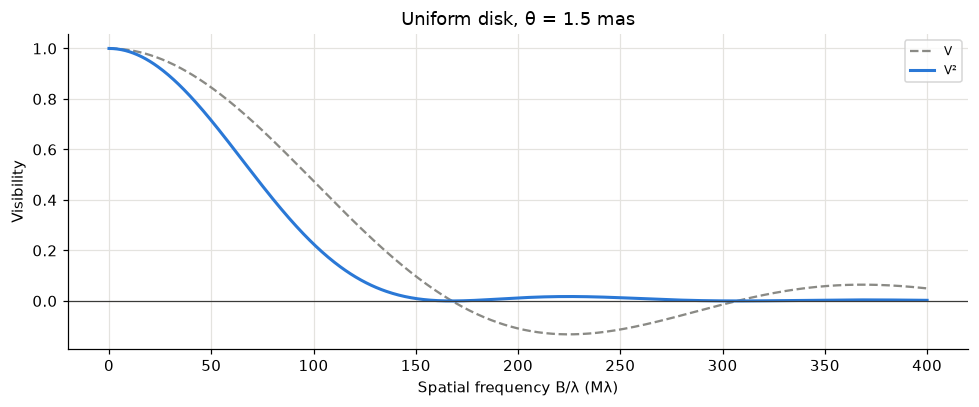

In [2]:
def x_of(theta_mas, spatial_freq):
    # spatial_freq is B / lambda in cycles per radian
    return np.pi * theta_mas * MAS_TO_RAD * np.maximum(spatial_freq, 1e-9)


def vis_ud(spatial_freq, theta_mas):
    x = x_of(theta_mas, spatial_freq)
    return 2 * j1(x) / x


fig, ax = plt.subplots(figsize=(9, 3.8))
sf = np.linspace(0, 400e6, 800)
ax.plot(sf / 1e6, vis_ud(sf, 1.5), color=GREY, lw=1.5, ls="--", label="V")
ax.plot(sf / 1e6, vis_ud(sf, 1.5) ** 2, color=BLUE, label="V²")
ax.axhline(0, color="#3a3a38", lw=0.8)
ax.set_xlabel("Spatial frequency B/λ (Mλ)")
ax.set_ylabel("Visibility")
ax.set_title("Uniform disk, θ = 1.5 mas")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

$V$ goes negative after the first zero. That sign is the 180° phase flip from notebook 03. $V^2$ folds it back up, so the first zero shows as a dip that touches zero.

## 2. Limb darkening

Look at a photo of the Sun. Its edge is darker than its centre. At the edge you look through the star's atmosphere at a slant and only see the cooler, dimmer upper layers. This is **limb darkening**, and every star has it.

A simple description is the **linear law**. Brightness drops from the centre to the edge as

$$I(\mu) = 1 - u\,(1 - \mu)$$

where $\mu$ goes from 1 at the centre to 0 at the edge, and $u$ is the limb-darkening coefficient. $u = 0$ is a uniform disk. For Sun-like stars in visible light, $u$ is about 0.6.

A limb-darkened star looks **smaller** than its true edge, because the edge is faint. If you fit a uniform disk to it, you get a diameter that is too small. The sliders compare the two.

In [3]:
def vis_ld(spatial_freq, theta_mas, u):
    # Linear limb darkening, Hanbury Brown et al. (1974). theta is the true (limb) diameter.
    x = x_of(theta_mas, spatial_freq)
    numerator = (1 - u) * j1(x) / x + u * np.sqrt(np.pi / 2) * jv(1.5, x) / x ** 1.5
    return numerator / ((1 - u) / 2 + u / 3)


def best_ud(theta_ld, u, sf):
    # Uniform-disk diameter that best matches the limb-darkened curve in the first lobe
    target = vis_ld(sf, theta_ld, u) ** 2
    grid = np.linspace(0.7 * theta_ld, theta_ld, 600)
    errors = [np.sum((vis_ud(sf, t) ** 2 - target) ** 2) for t in grid]
    return grid[int(np.argmin(errors))]


@interact(
    u=FloatSlider(value=0.6, min=0.0, max=1.0, step=0.05, description="u",
                  continuous_update=False, style=SLIDER_STYLE),
)
def show_limb_darkening(u):
    theta = 1.5
    r = np.linspace(0, 1, 300)
    mu = np.sqrt(1 - r ** 2)
    profile = 1 - u * (1 - mu)

    axis = np.linspace(-1.1, 1.1, 301)
    xx, yy = np.meshgrid(axis, axis)
    rr = np.hypot(xx, yy)
    image = np.where(rr <= 1, 1 - u * (1 - np.sqrt(np.clip(1 - rr ** 2, 0, 1))), 0)

    sf = np.linspace(0, 400e6, 800)
    first_lobe = sf[sf < 1.22 / (theta * MAS_TO_RAD)]
    theta_ud = best_ud(theta, u, first_lobe)

    fig = plt.figure(figsize=(12, 4))
    gs = GridSpec(1, 3, figure=fig, width_ratios=[1, 1.1, 1.8])
    ax_img = fig.add_subplot(gs[0])
    ax_img.imshow(image, extent=[-1.1, 1.1, -1.1, 1.1], cmap="inferno", vmin=0, vmax=1)
    ax_img.set_title(f"Star with u = {u:.2f}", fontsize=10)
    ax_img.axis("off")

    ax_prof = fig.add_subplot(gs[1])
    ax_prof.plot(r, profile, color=BLUE, label="limb darkened")
    ax_prof.plot(r, np.ones_like(r), color=GREY, ls="--", lw=1.5, label="uniform")
    ax_prof.set_ylim(0, 1.1)
    ax_prof.set_xlabel("Distance from centre (fraction of radius)")
    ax_prof.set_ylabel("Brightness")
    ax_prof.set_title("Brightness across the disk", fontsize=10)
    ax_prof.legend(fontsize=8, loc="lower left")

    ax_v = fig.add_subplot(gs[2])
    ax_v.plot(sf / 1e6, vis_ld(sf, theta, u) ** 2, color=BLUE,
              label=f"limb darkened, θ_LD = {theta:.2f} mas")
    ax_v.plot(sf / 1e6, vis_ud(sf, theta_ud) ** 2, color=ORANGE, ls="--", lw=1.5,
              label=f"best uniform disk, θ_UD = {theta_ud:.2f} mas")
    ax_v.set_yscale("log")
    ax_v.set_ylim(1e-4, 1.2)
    ax_v.set_xlabel("Spatial frequency B/λ (Mλ)")
    ax_v.set_ylabel("V² (log scale)")
    ax_v.set_title("Visibility: nearly the same until the second lobe", fontsize=10)
    ax_v.legend(fontsize=8, loc="lower left")
    plt.tight_layout()
    plt.show()
    print(f"A uniform-disk fit under-sizes this star by {100 * (1 - theta_ud / theta):.1f}%.")

interactive(children=(FloatSlider(value=0.6, continuous_update=False, description='u', max=1.0, step=0.05, sty…

**Try this:**

- At $u = 0$ the two curves are the same star.
- Raise $u$. In the first lobe the limb-darkened star looks like a smaller uniform disk. The curves only separate after the first zero, in the second lobe (the log scale makes it visible).

**The practical consequence:** if your data only cover the first lobe, they cannot tell you $u$. You fit a uniform disk, then convert to the true diameter using $u$ from stellar atmosphere models. Data in the second lobe can measure $u$ directly, which tests those models.

## 3. Fitting a diameter to noisy data

A real measurement is a set of $V^2$ points with error bars, one per baseline and wavelength. **Fitting** means finding the diameter whose model curve passes closest to the points. "Closest" is measured by

$$\chi^2 = \sum_i \left(\frac{V^2_{\text{data},i} - V^2_{\text{model},i}}{\sigma_i}\right)^2$$

the sum of squared misses, each scaled by its error bar. The best diameter minimises $\chi^2$. How sharp the minimum is gives the uncertainty.

The cell below simulates an observation of a uniform-disk star at 1.65 µm with random baselines, then fits it.

In [4]:
@interact(
    true_theta=FloatSlider(value=1.0, min=0.2, max=3.0, step=0.05, description="true θ (mas)",
                           continuous_update=False, style=SLIDER_STYLE),
    max_baseline=FloatSlider(value=331, min=50, max=331, step=1, description="max B (m)",
                             continuous_update=False, style=SLIDER_STYLE),
    noise=FloatSlider(value=0.03, min=0.005, max=0.1, step=0.005, description="σ(V²)",
                      readout_format=".3f", continuous_update=False, style=SLIDER_STYLE),
    n_points=IntSlider(value=20, min=3, max=100, step=1, description="points",
                       continuous_update=False, style=SLIDER_STYLE),
)
def show_fit(true_theta, max_baseline, noise, n_points):
    wavelength = 1.65e-6
    rng = np.random.default_rng(1)
    baselines = rng.uniform(CHARA_MIN, max_baseline, n_points)
    sf = baselines / wavelength
    data = vis_ud(sf, true_theta) ** 2 + rng.normal(0, noise, n_points)
    errors = np.full(n_points, noise)

    model = lambda s, theta: vis_ud(s, theta) ** 2
    (theta_fit,), cov = curve_fit(model, sf, data, p0=[1.0], sigma=errors,
                                  absolute_sigma=True, bounds=(0.01, 10))
    theta_err = np.sqrt(cov[0, 0])

    half_width = max(4 * theta_err, 0.02)
    grid = np.linspace(max(0.01, theta_fit - half_width), theta_fit + half_width, 400)
    chi2 = np.array([np.sum(((data - model(sf, t)) / errors) ** 2) for t in grid])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    curve_sf = np.linspace(0, CHARA_MAX / wavelength, 500)
    ax1.errorbar(baselines, data, yerr=errors, fmt="o", ms=4, color=BLUE,
                 ecolor="#9ec5f4", label="simulated data")
    ax1.plot(curve_sf * wavelength, model(curve_sf, true_theta), color=GREY, ls="--", lw=1.5,
             label=f"true θ = {true_theta:.2f} mas")
    ax1.plot(curve_sf * wavelength, model(curve_sf, theta_fit), color=ORANGE, lw=1.5,
             label=f"fit θ = {theta_fit:.3f} ± {theta_err:.3f} mas")
    ax1.set_ylim(-0.15, 1.15)
    ax1.set_xlabel("Baseline (m)")
    ax1.set_ylabel("V²")
    ax1.set_title("Data and fitted model", fontsize=10)
    ax1.legend(fontsize=8, loc="upper right")

    ax2.plot(grid, chi2 - chi2.min(), color=BLUE)
    ax2.axhline(1, color=GREY, ls="--", lw=1, label="Δχ² = 1 (1σ range)")
    ax2.axvline(true_theta, color=GREY, lw=1)
    ax2.set_ylim(0, 16)
    ax2.set_xlabel("Trial diameter θ (mas)")
    ax2.set_ylabel("χ² − minimum")
    ax2.set_title("How χ² changes with the trial diameter", fontsize=10)
    ax2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    print(f"Fitted θ = {theta_fit:.3f} ± {theta_err:.3f} mas "
          f"({100 * theta_err / theta_fit:.1f}% precision)")

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='true θ (mas)', max=3.0, min…

**Try this:**

- Set the true diameter to 0.3 mas. The data only drop to about 0.8, and the printed precision gets several times worse. The star is only just resolved.
- Keep 0.3 mas and lower the noise to 0.005. Precise data recover a diameter well below $\lambda/B$. This is how CHARA measures stars smaller than its quoted resolution.
- Set 1.0 mas and cut the max baseline to 60 m. The precision gets worse: short baselines see less of the drop.

## 4. Real data: δ Cephei

δ Cephei is the prototype **Cepheid variable**, a supergiant that swells and shrinks with a period of 5.37 days. Cepheids anchor the cosmic distance scale, because their pulsation period predicts their true brightness.

The data below are public CHARA measurements from the **VEGA** instrument, which works in visible light (0.50 to 0.75 µm). They are from Nardetto et al. (2016, A&A 593, A45). They are served by the JMMC Optical Interferometry Database (OiDB).

The next cell queries the database and downloads the files into `data/delta_cep/`, about 6 MB. After the first run it reads the local copy.

In [5]:
TAP_URL = "https://tap.jmmc.fr/vollt/tap/sync"
OIDB_URL = "https://oidb.jmmc.fr"
DATA_DIR = Path("data/delta_cep")
QUERY = ("SELECT access_url FROM oidb WHERE facility_name = 'CHARA' "
         "AND data_rights = 'public' AND calib_level = 3 AND target_name = 'HD213306'")


def download_delta_cep():
    done_marker = DATA_DIR / ".complete"
    if done_marker.exists():
        return sorted(DATA_DIR.glob("*.oifits"))
    DATA_DIR.mkdir(parents=True, exist_ok=True)

    params = urllib.parse.urlencode({"REQUEST": "doQuery", "LANG": "ADQL",
                                     "FORMAT": "csv", "QUERY": QUERY}).encode()
    with urllib.request.urlopen(TAP_URL, data=params, timeout=60) as response:
        rows = list(csv.DictReader(io.StringIO(response.read().decode())))

    def fetch(row):
        url = urllib.parse.urljoin(OIDB_URL, row["access_url"])
        target = DATA_DIR / Path(urllib.parse.urlparse(url).path).name
        if not target.exists():
            urllib.request.urlretrieve(url, target)

    with ThreadPoolExecutor(max_workers=8) as pool:
        list(pool.map(fetch, rows))
    done_marker.touch()
    return sorted(DATA_DIR.glob("*.oifits"))


def load_vis2(files):
    records = []
    for path in files:
        with fits.open(path) as hdul:
            stations = {row["STA_INDEX"]: row["TEL_NAME"].strip() for row in hdul["OI_ARRAY"].data}
            wavelengths = np.atleast_1d(hdul["OI_WAVELENGTH"].data["EFF_WAVE"])
            for row in hdul["OI_VIS2"].data:
                pair = "-".join(sorted(stations[i] for i in row["STA_INDEX"]))
                for wl, v2, err, flag in zip(wavelengths, np.atleast_1d(row["VIS2DATA"]),
                                             np.atleast_1d(row["VIS2ERR"]),
                                             np.atleast_1d(row["FLAG"])):
                    if not flag:
                        records.append((row["MJD"], wl, row["UCOORD"], row["VCOORD"], v2, err, pair))
    mjd, wl, u, v, v2, err, pair = map(np.array, zip(*records))
    return dict(mjd=mjd.astype(float), wavelength=wl.astype(float), u=u.astype(float),
                v=v.astype(float), vis2=v2.astype(float), err=err.astype(float), pair=pair)


files = download_delta_cep()
obs = load_vis2(files)
obs["sf"] = np.hypot(obs["u"], obs["v"]) / obs["wavelength"]
print(f"{len(files)} files, {len(obs['vis2'])} V² points, "
      f"{len(np.unique(obs['mjd'].astype(int)))} nights")
print(f"Telescope pairs: {sorted(set(obs['pair']))}")
print(f"Baselines {np.hypot(obs['u'], obs['v']).min():.0f} to {np.hypot(obs['u'], obs['v']).max():.0f} m, "
      f"wavelengths {obs['wavelength'].min() * 1e6:.2f} to {obs['wavelength'].max() * 1e6:.2f} µm")

179 files, 179 V² points, 23 nights
Telescope pairs: [np.str_('E1-E2'), np.str_('S1-S2')]
Baselines 27 to 66 m, wavelengths 0.50 to 0.75 µm


These observations used CHARA's two **shortest** telescope pairs. δ Cep is about 1.5 mas across, so in visible light even 30 to 66 m baselines resolve it well.

The left plot shows where the measurements sit in the uv plane (notebook 03). Each point is one baseline at one moment, plus its mirror point. Earth's rotation turns the baselines, which spreads the points into arcs (topic T5). The right plot shows all the $V^2$ points against spatial frequency, coloured by wavelength.

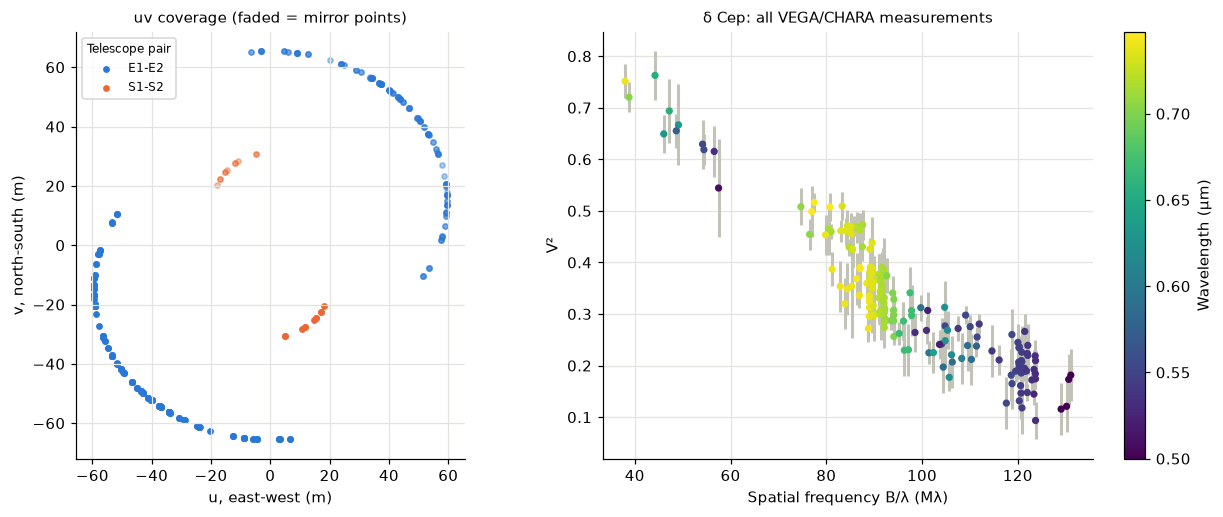

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
for pair, colour in zip(sorted(set(obs["pair"])), [BLUE, ORANGE]):
    m = obs["pair"] == pair
    ax1.scatter(obs["u"][m], obs["v"][m], s=12, color=colour, label=pair)
    ax1.scatter(-obs["u"][m], -obs["v"][m], s=12, color=colour, alpha=0.4)
ax1.set_aspect("equal")
ax1.set_xlabel("u, east-west (m)")
ax1.set_ylabel("v, north-south (m)")
ax1.set_title("uv coverage (faded = mirror points)", fontsize=10)
ax1.legend(fontsize=8, title="Telescope pair", title_fontsize=8)

points = ax2.scatter(obs["sf"] / 1e6, obs["vis2"], c=obs["wavelength"] * 1e6, cmap="viridis",
                     s=14, zorder=3)
ax2.errorbar(obs["sf"] / 1e6, obs["vis2"], yerr=obs["err"], fmt="none", ecolor="#c3c2b7",
             zorder=2)
fig.colorbar(points, ax=ax2, label="Wavelength (µm)")
ax2.set_xlabel("Spatial frequency B/λ (Mλ)")
ax2.set_ylabel("V²")
ax2.set_title("δ Cep: all VEGA/CHARA measurements", fontsize=10)
plt.tight_layout()
plt.show()

Now fit. The data only reach partway down the first lobe, so (from section 2) they cannot measure the limb darkening. The fit uses a fixed $u$ from stellar atmosphere models. For a star of δ Cep's temperature in visible light that is about 0.6.

Move the $u$ slider. The fitted true diameter changes while the fit quality (χ²) barely moves. **The data cannot choose $u$.** That is why the assumed value matters.

**Reduced χ²** is χ² divided by the number of points minus fitted parameters. If the error bars are right and the model fits, it is about 1. Larger means the scatter exceeds the error bars. The usual practice is then to scale the uncertainty by $\sqrt{\chi^2_\text{red}}$.

In [7]:
@interact(
    u=FloatSlider(value=0.6, min=0.0, max=1.0, step=0.05, description="u",
                  continuous_update=False, style=SLIDER_STYLE),
)
def fit_delta_cep(u):
    sf, data, err = obs["sf"], obs["vis2"], obs["err"]
    model = lambda s, theta: vis_ld(s, theta, u) ** 2
    (theta,), cov = curve_fit(model, sf, data, p0=[1.5], sigma=err, absolute_sigma=True)
    resid = (data - model(sf, theta)) / err
    chi2_red = np.sum(resid ** 2) / (len(data) - 1)
    theta_err = np.sqrt(cov[0, 0]) * np.sqrt(chi2_red)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 1]})
    curve = np.linspace(1e6, sf.max() * 1.6, 500)
    ax1.errorbar(sf / 1e6, data, yerr=err, fmt="o", ms=3, color=BLUE, ecolor="#9ec5f4",
                 label="VEGA/CHARA data")
    ax1.plot(curve / 1e6, model(curve, theta), color=ORANGE,
             label=f"limb-darkened disk, u = {u:.2f}: θ = {theta:.3f} ± {theta_err:.3f} mas")
    ax1.set_ylim(-0.05, 1.05)
    ax1.set_ylabel("V²")
    ax1.set_title(f"δ Cep fit, reduced χ² = {chi2_red:.2f}", fontsize=10)
    ax1.legend(fontsize=8, loc="upper right")

    ax2.scatter(sf / 1e6, resid, s=8, color=BLUE)
    ax2.axhline(0, color=GREY, lw=1)
    ax2.set_xlabel("Spatial frequency B/λ (Mλ)")
    ax2.set_ylabel("(data − model) / σ")
    plt.tight_layout()
    plt.show()

    print(f"Limb-darkened diameter: {theta:.3f} ± {theta_err:.3f} mas "
          f"(error scaled by √χ²_red = {np.sqrt(chi2_red):.2f})")

interactive(children=(FloatSlider(value=0.6, continuous_update=False, description='u', max=1.0, step=0.05, sty…

With $u = 0.6$ the fit gives a limb-darkened diameter of about 1.47 mas. Published values for δ Cep's mean diameter are close to 1.5 mas.

The reduced χ² is about 4. The points scatter more than their error bars allow. The residuals also show a **pattern**: below the model at low spatial frequency, above it at high. Random noise would scatter evenly around zero. A pattern means the model's shape is wrong, not just the error bars.

Three effects contribute. All are real-data lessons:

- **The star pulsates.** Its diameter changes by several percent over 5.37 days, and this fit treats all nights as one star.
- **Calibration.** Each $V^2$ is calibrated against reference stars of known size. Errors in that step shift whole nights up or down together.

- **An envelope.** The paper's authors found that a few percent of the light comes from a faint, extended envelope around the star. Extended light is resolved even on short baselines, so it lowers $V^2$ there. That matches the residual pattern.

## 5. From angular size to true size

An angle becomes a size once you know the distance. A star of angular diameter $\theta$ at distance $d$ has radius

$$R = \frac{\theta\, d}{2}$$

with $\theta$ in radians. δ Cep's distance is about 272 parsecs, from its parent star cluster and from Hubble Space Telescope parallax.

In [8]:
R_SUN = 6.957e8      # m
PARSEC = 3.0857e16   # m

(theta_ld_mas,), _ = curve_fit(lambda s, t: vis_ld(s, t, 0.6) ** 2, obs["sf"], obs["vis2"],
                               p0=[1.5], sigma=obs["err"])
distance_pc = 272

print(f"θ_LD = {theta_ld_mas:.3f} mas (u = 0.6 fit)")

radius_m = theta_ld_mas * MAS_TO_RAD * distance_pc * PARSEC / 2
print(f"Radius: {radius_m / 1e3:,.0f} km = {radius_m / R_SUN:.0f} solar radii")
print(f"If δ Cep replaced the Sun, its surface would reach {radius_m / 1.496e11:.2f} AU "
      f"(Mercury orbits at 0.39 AU).")

θ_LD = 1.470 mas (u = 0.6 fit)
Radius: 29,909,681 km = 43 solar radii
If δ Cep replaced the Sun, its surface would reach 0.20 AU (Mercury orbits at 0.39 AU).


## 6. Can we see it pulsate?

δ Cep's brightness and size follow its 5.37-day cycle. The **pulsation phase** says where in the cycle each night falls (0 = maximum brightness). The cell below fits each night separately and plots the diameter against phase. A clean result would trace a smooth loop of a few percent.

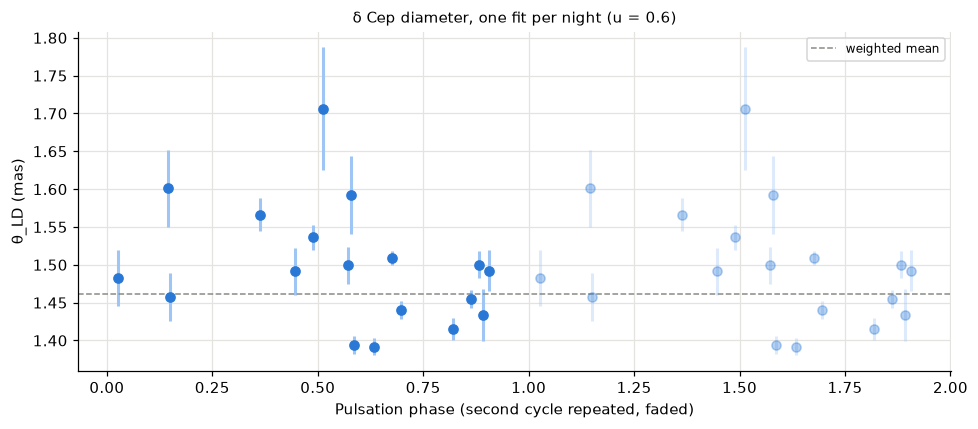

18 nights with 4+ points. Spread of diameters: 0.078 mas, typical error bar: 0.023 mas


In [9]:
PERIOD_D = 5.366341          # δ Cep period, GCVS
EPOCH_MJD = 2436075.445 - 2400000.5  # a time of maximum brightness, GCVS

nights = obs["mjd"].astype(int)
results = []
for night in np.unique(nights):
    m = nights == night
    if m.sum() < 4:
        continue
    (theta,), cov = curve_fit(lambda s, t: vis_ld(s, t, 0.6) ** 2, obs["sf"][m], obs["vis2"][m],
                              p0=[1.5], sigma=obs["err"][m], absolute_sigma=True)
    phase = ((obs["mjd"][m].mean() - EPOCH_MJD) / PERIOD_D) % 1
    results.append((phase, theta, np.sqrt(cov[0, 0]), m.sum()))
phase, theta, theta_err, count = map(np.array, zip(*results))

fig, ax = plt.subplots(figsize=(9, 4))
for shift in (0, 1):
    ax.errorbar(phase + shift, theta, yerr=theta_err, fmt="o", color=BLUE, ecolor="#9ec5f4",
                alpha=1 if shift == 0 else 0.35)
ax.axhline(np.average(theta, weights=1 / theta_err ** 2), color=GREY, ls="--", lw=1,
           label="weighted mean")
ax.set_xlabel("Pulsation phase (second cycle repeated, faded)")
ax.set_ylabel("θ_LD (mas)")
ax.set_title("δ Cep diameter, one fit per night (u = 0.6)", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"{len(theta)} nights with 4+ points. Spread of diameters: {theta.std():.3f} mas, "
      f"typical error bar: {np.median(theta_err):.3f} mas")

The nightly diameters scatter much more than their error bars, and no clean loop emerges. Nights at nearly the same phase disagree by up to 10%. The scatter comes from calibration and the envelope, not the pulsation. Measuring Cepheid pulsation by interferometry needs longer baselines, careful calibration and many nights. It has been done for δ Cep in the infrared (Mérand et al. 2005, with CHARA's FLUOR instrument).

This is a fair picture of real data. A simple model gets you a good mean diameter quickly. The finer question needs more data and better systematics than this public set has.

## Summary

| Step | Key point |
|---|---|
| Measure $V^2$ | Survives the atmosphere. Plotted against spatial frequency $B/\lambda$ |
| Limb darkening | Stars are fainter at the edge. A uniform-disk fit under-sizes them by a few percent |
| First lobe only | Cannot measure limb darkening. Take $u$ from models |
| Fit | Minimise χ². Scale errors by $\sqrt{\chi^2_\text{red}}$ when scatter exceeds error bars |
| δ Cep | θ_LD ≈ 1.47 mas, R ≈ 43 R☉ at 272 pc |

**Next:** T5, uv coverage. How the layout of CHARA's six telescopes and Earth's rotation decide which parts of the uv plane get measured.